# UConn SDP Team 46 — Adaptive preprocessing for TimesFM 3.0 and Chronos-2

**Goal:** take the 21 kinds of time series from `RESULTS.pdf` (17 synthetic types + 4 real datasets, 103 forecasts),
preprocess each series in a way that fits *both the data and the model*, forecast with **TimesFM 3.0**
(`google/timesfm-3.0-pytorch`) and **Chronos-2** (`amazon/chronos-2`), and compare accuracy **before vs. after** preprocessing.

**How the pipeline works**

1. **Profile** every context window: missing values, zeros, positivity, seasonal/trend strength (robust STL),
   multiplicative structure, unit root (ADF), outliers, level shifts, length.
2. **Rules → recipe.** The profile picks preprocessing steps, and the rules are **model-specific**
   (table below), because both models already normalize internally and handle some problems on their own.
3. **Validation gate (no leakage).** The last 1–3 horizons *inside the context* are used as a validation backtest.
   The rule recipe, each leave-one-step-out variant and "no preprocessing" compete; a recipe is kept only if it
   beats raw by ≥ 5% mean validation MASE **and** wins at least 2 of 3 validation windows. This keeps a step from
   hurting a series where the rule fired by mistake, or where one lucky window made it look good.
4. **Interval calibration (post-processing).** The PDF found 80% bands that covered only 62–65% on some types.
   When validation coverage is more than 10 points under 80%, the 10–90% band is widened around the median
   until validation coverage reaches 80% (widen-only: a few short windows are too noisy to justify narrowing).
5. **Forecast, invert, score.** Every transform is inverted on the forecast quantiles; we report MASE, scaled
   quantile loss (SQL) and 80%-band coverage for three variants: **Raw**, **Rules-only**, **Adaptive** (rules + gate + calibration).

### Why these steps, and why they differ per model

| Step | Triggered when | TimesFM 3.0 | Chronos-2 | Reason |
|---|---|:-:|:-:|---|
| Seasonal-aware imputation (STL) | NaNs in context | ✔ | ✘ | TimesFM fills gaps by **straight-line interpolation** inside `predict_batch`, which flattens the cycle inside a gap. Chronos-2 takes NaN as a **missing-value mask** natively, so imputing would show it invented values as if observed. |
| Robust outlier repair (STL residual, \|z\| > 7) | 0 < outlier share ≤ 3% | ✔ | ✔ | Both scale inputs by context statistics (TimesFM RevIN, Chronos-2 robust scaling); isolated spikes distort that scale and can be copied into the forecast. |
| Box-Cox (Guerrero λ) | positive and multiplicative / exponential | ✔ | ✔ | Both models are **affine-equivariant** (TimesFM guarantees f(aX+b) = a·f(X)+b). An affine scaling cannot remove amplitude that grows with the level; a log/power transform makes it additive. |
| Level-shift alignment | a sharp step (> 6σ, > 50% of variance) whose residual is stationary, found on the Box-Cox scale | ✔ | ✔ | Attention over the full history lets the old regime pull the forecast; aligning keeps the seasonal history but removes the stale level. |
| Differencing | unit root (ADF p > 0.1, weak seasonality) | ✔ | ✔ | On random walks / price-like series both models extrapolated spurious drift (PDF: worse than last value). Differences are close to white noise, so the integrated forecast stays near the last value; bands widen as √(steps). |
| Non-negativity clip | context ≥ 0 | ✔ | ✔ | Counts / sparse demand cannot be negative. |

**Deliberately not used:** global z-score / min-max scaling (redundant — both models are affine-equivariant, so it
changes nothing), linear detrending (TimesFM 3.0 already runs `use_linear_detrending=True`, Chronos-2 handles trends),
smoothing (it removes the noise the models use to size their uncertainty, giving bands that are too narrow), and
truncating long histories to a recent window (tried on ETTh1: it raised TimesFM's MASE by ~30%; both models use
long context well — TimesFM reads up to 15,360 points, Chronos-2 up to 8,192).

> Runs on Colab (GPU recommended) or locally. The model weights download on the first run.

## 1. Install and configure

In [1]:
%pip -q install "timesfm==3.0.2" "chronos-forecasting>=2.3" "statsmodels>=0.14" scipy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
import math
import os
import time
import warnings
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy import stats
from statsmodels.stats.diagnostic import het_arch
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")

SEED = 46
N_PER_TYPE = 5                 # synthetic series per data type (as in RESULTS.pdf)
QUANTILES = [0.1, 0.5, 0.9]    # 10-90% band + median
GATE_MARGIN = 0.05             # preprocessing must beat raw by 5% on validation ...
GATE_MAJORITY = 2 / 3          # ... and win at least 2 of 3 validation windows
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT_DIR = "preprocessing_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
torch.manual_seed(SEED)

# Colors: neutral gray = before (raw), blue = after (adaptive); model identity uses fixed slots.
C_RAW, C_RULES, C_ADAPT, C_ACTUAL = "#a3a29c", "#9cc0ec", "#2a78d6", "#0b0b0b"
C_MODEL = {"TimesFM 3.0": "#2a78d6", "Chronos-2": "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "legend.frameon": False, "lines.linewidth": 1.6,
})
print("Device:", DEVICE)

Device: cpu


## 2. Data: the 21 types from RESULTS.pdf

Synthetic generators mirror the PDF's 17 types (5 seeded series each). Real data uses rolling test windows:
Air passengers (3 windows), Sunspots, Daily min temperature and ETTh1 oil temperature (5 windows each).
The future window is never visible to preprocessing or validation.

In [ ]:
@dataclass
class Task:
    name: str            # data type
    group: str           # "Synthetic" or "Real"
    sid: str             # unique series id
    context: np.ndarray  # history given to the model (may contain NaN)
    future: np.ndarray   # held-out truth
    season: int          # cycle length used by the seasonal-naive baseline (1 = none)

    @property
    def horizon(self):
        return len(self.future)


def _sin(t, period, phase=0.0):
    return np.sin(2 * np.pi * t / period + phase)


def gen_seasonal_trend(r, n=1000):
    t = np.arange(n, dtype=float)
    return 10 + 0.01 * t + 3 * _sin(t, 24, r.uniform(0, 2 * np.pi)) + r.normal(0, 0.5, n)


def gen_multi_seasonal(r):
    t = np.arange(1344, dtype=float)
    return 50 + 5 * _sin(t, 24, r.uniform(0, 6.28)) + 8 * _sin(t, 168, r.uniform(0, 6.28)) + r.normal(0, 1, t.size)


def gen_multiplicative(r):
    t = np.arange(600, dtype=float)
    level = 20 + 0.06 * t
    return level * (1 + 0.3 * _sin(t, 24, r.uniform(0, 6.28))) * (1 + r.normal(0, 0.02, t.size))


def gen_square(r):
    t = np.arange(800, dtype=float)
    return 5 * np.sign(_sin(t, 50, r.uniform(0, 6.28)) + 1e-9) + r.normal(0, 0.3, t.size)


def gen_sawtooth(r):
    t = np.arange(800, dtype=float)
    return 10 * ((t + r.integers(0, 32)) % 32) / 32 + r.normal(0, 0.2, t.size)


def gen_linear(r):
    t = np.arange(500, dtype=float)
    return 40 + 0.08 * t + r.normal(0, 1.5, t.size)


def gen_exponential(r):
    t = np.arange(400, dtype=float)
    return 5 * np.exp(0.006 * t) * (1 + r.normal(0, 0.02, t.size))


def gen_random_walk(r):
    return 80 + np.cumsum(r.normal(0, 1, 1000))


def gen_white_noise(r):
    return r.normal(0, 1, 1000)


def gen_level_shift(r):
    t = np.arange(1000, dtype=float)
    y = 10 + 3 * _sin(t, 50, r.uniform(0, 6.28)) + r.normal(0, 0.5, t.size)
    return y + 8 * (t >= r.integers(500, 800))


def gen_outliers(r):
    t = np.arange(1000, dtype=float)
    y = 10 + 2 * _sin(t, 40, r.uniform(0, 6.28)) + r.normal(0, 0.5, t.size)
    idx = r.choice(1000 - 40, 10, replace=False)   # spikes only in the history
    y[idx] += r.choice([-1, 1], 10) * r.uniform(10, 20, 10)
    return y


def gen_intermittent(r):
    n = 730
    return np.where(r.random(n) < 0.15, np.round(1 + r.gamma(2.0, 1.5, n)), 0.0)


def gen_volatility(r):
    n = 1000
    ret, s2 = np.zeros(n), np.full(n, 1e-4)
    for i in range(1, n):   # GARCH(1,1) log-returns -> price
        s2[i] = 2e-6 + 0.12 * ret[i - 1] ** 2 + 0.86 * s2[i - 1]
        ret[i] = np.sqrt(s2[i]) * r.standard_normal()
    return 90 * np.exp(np.cumsum(ret))


def gen_logistic(r):
    x = np.empty(1000)
    x[0] = r.uniform(0.1, 0.9)
    for i in range(1, 1000):
        x[i] = 3.9 * x[i - 1] * (1 - x[i - 1])
    return x + r.normal(0, 0.01, 1000)


def gen_short(r):
    t = np.arange(64 + 24, dtype=float)
    return 12 + 3 * _sin(t, 12, r.uniform(0, 6.28)) + r.normal(0, 0.5, t.size)


def gen_missing(r, h=48):
    y = gen_seasonal_trend(r)
    for _ in range(3):   # contiguous gaps, all before the forecast window
        s = r.integers(100, y.size - h - 40)
        y[s:s + r.integers(15, 36)] = np.nan
    rand = r.random(y.size) < 0.05
    rand[-h:] = False
    y[rand] = np.nan
    return y


def gen_long_horizon(r):
    t = np.arange(1500, dtype=float)
    return 10 + 0.01 * t + (2 + 0.002 * t) * _sin(t, 24, r.uniform(0, 6.28)) + r.normal(0, 0.4, t.size)


# name: (generator, season, horizon)
SYNTH_SPECS = {
    "Seasonal + trend": (gen_seasonal_trend, 24, 48),
    "Multi-seasonal (daily + weekly)": (gen_multi_seasonal, 168, 168),
    "Multiplicative seasonal": (gen_multiplicative, 24, 48),
    "Square wave": (gen_square, 50, 50),
    "Sawtooth": (gen_sawtooth, 32, 48),
    "Linear trend": (gen_linear, 1, 48),
    "Exponential growth": (gen_exponential, 1, 48),
    "Random walk": (gen_random_walk, 1, 48),
    "White noise": (gen_white_noise, 1, 48),
    "Level shift": (gen_level_shift, 50, 50),
    "Outliers in history": (gen_outliers, 40, 40),
    "Intermittent demand": (gen_intermittent, 7, 28),
    "Volatility clustering": (gen_volatility, 1, 48),
    "Chaotic (logistic map)": (gen_logistic, 1, 24),
    "Short history (64 points)": (gen_short, 12, 24),
    "Missing values (gaps)": (gen_missing, 24, 48),
    "Long horizon (256 steps)": (gen_long_horizon, 24, 256),
}

tasks = []
rng = np.random.default_rng(SEED)
for name, (gen, season, h) in SYNTH_SPECS.items():
    for i in range(N_PER_TYPE):
        y = gen(np.random.default_rng(rng.integers(1 << 31))).astype(float)
        tasks.append(Task(name, "Synthetic", f"{name}#{i}", y[:-h], y[-h:], season))


def rolling_tasks(name, y, season, horizon, n_windows, stride):
    out = []
    for k in range(n_windows):
        end = len(y) - k * stride
        out.append(Task(name, "Real", f"{name}#w{k}", y[:end - horizon].copy(), y[end - horizon:end].copy(), season))
    return out


air = pd.read_csv("https://autogluon.s3.us-west-2.amazonaws.com/datasets/timeseries/misc/AirPassengers.csv")["#Passengers"]
sun = pd.read_csv("https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-sunspots.csv")["Sunspots"]
temp = pd.read_csv("https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv")["Temp"]
ett = pd.read_csv("https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv")["OT"]

REAL_SPECS = {   # name: (values, season, horizon, windows, stride)
    "Air passengers (monthly)": (air, 12, 12, 3, 12),
    "Sunspots (monthly)": (sun, 132, 24, 5, 120),     # ~11-year solar cycle
    "Min temperature (daily)": (temp, 365, 30, 5, 180),
    "ETTh1 oil temperature (hourly)": (ett, 24, 48, 5, 500),
}
for name, (values, season, h, w, stride) in REAL_SPECS.items():
    tasks += rolling_tasks(name, pd.to_numeric(values).to_numpy(float), season, h, w, stride)

TYPE_ORDER = list(SYNTH_SPECS) + list(REAL_SPECS)
GROUP = {t.name: t.group for t in tasks}
print(f"{len(tasks)} forecasts across {len(TYPE_ORDER)} data types")

103 forecasts across 21 data types


: 

## 3. Series profiler

Every diagnostic is computed **only on the context** the model will see, never on the future.

In [ ]:
OUTLIER_Z = 7.0   # robust z-score above which a residual counts as an outlier


def fill_linear(x):
    return pd.Series(x).interpolate(limit_direction="both").to_numpy()


def rsd(v):
    """Robust standard deviation (1.4826 x MAD)."""
    v = v[~np.isnan(v)]
    return 1.4826 * np.median(np.abs(v - np.median(v))) + 1e-12


def decompose(x, m):
    """Robust trend / seasonal / residual split: STL when a cycle is known, rolling median otherwise."""
    xf = fill_linear(x)
    if m > 1 and len(xf) >= 2 * m + 1:
        # R-style loess jumps (window/10) keep robust STL fast for long cycles such as m=365.
        trend_win = int(np.ceil(1.5 * m / (1 - 1.5 / 7))) | 1
        res = STL(xf, period=m, robust=True, trend=trend_win,
                  seasonal_jump=1, trend_jump=max(1, trend_win // 10), low_pass_jump=max(1, m // 10)).fit()
        return res.trend, res.seasonal, res.resid
    w = max(5, min(25, len(xf) // 10)) | 1
    trend = pd.Series(xf).rolling(w, center=True, min_periods=1).median().to_numpy()
    return trend, np.zeros_like(xf), xf - trend


def guerrero_lambda(x, m, grid=np.linspace(0, 1, 11)):
    """Box-Cox lambda that makes the spread of sub-series most constant relative to their level."""
    p = m if m > 1 else max(4, len(x) // 20)
    k = len(x) // p
    seg = x[-k * p:].reshape(k, p)
    mu, sd = np.nanmean(seg, 1), np.nanstd(seg, 1, ddof=1)
    ok = (mu > 0) & (sd > 0)
    mu, sd = mu[ok], sd[ok]
    if len(mu) < 3:
        return 0.0
    cv = [np.std(sd / mu ** (1 - lam)) / np.mean(sd / mu ** (1 - lam)) for lam in grid]
    return float(grid[int(np.argmin(cv))])


def is_multiplicative(xf, m):
    if m > 1 and len(xf) >= 3 * m:
        k = len(xf) // m
        seg = xf[-k * m:].reshape(k, m)
        level, amp = seg.mean(1), seg.std(1)
        return level.max() / level.min() > 1.3 and np.corrcoef(level, amp)[0, 1] > 0.6
    # No cycle: exponential growth is a straight line on a log scale.
    t = np.arange(len(xf))
    r2 = lambda v: np.corrcoef(t, v)[0, 1] ** 2
    q = len(xf) // 4
    return xf[-q:].mean() / xf[:q].mean() > 2 and r2(np.log(xf)) > max(0.9, r2(xf) + 0.01)


def find_level_shift(x, m, seas=None):
    """Single step change (tau, size) on the deseasonalized series, or None.

    Accepted only if the step explains >50% of the variance left by a line, is > 6 noise sigmas,
    and the residual is stationary (so a random walk's wandering is not mistaken for a shift)."""
    if seas is None:
        seas = decompose(x, m)[1]
    d = fill_linear(x) - seas
    n, w = len(d), max(2 * m, 30)
    if n < 3 * w:
        return None
    t = np.arange(n, dtype=float)
    X0 = np.column_stack([np.ones(n), t])
    v0 = np.var(d - X0 @ np.linalg.lstsq(X0, d, rcond=None)[0])
    best = None
    for tau in np.unique(np.linspace(w, n - w, 120).astype(int)):
        X = np.column_stack([X0, (t >= tau).astype(float)])
        beta = np.linalg.lstsq(X, d, rcond=None)[0]
        r = d - X @ beta
        if best is None or r.var() < best[0]:
            best = (r.var(), tau, beta[2], r)
    v, tau, c, r = best
    noise = rsd(np.diff(d)) / np.sqrt(2)
    if v < 0.5 * v0 and abs(c) > 6 * noise and adfuller(r[-2000:], autolag="AIC")[1] < 0.05:
        return int(tau), float(c)
    return None


@dataclass
class Profile:
    n: int
    missing: float
    zero_frac: float
    nonneg: bool
    positive: bool
    seas_strength: float
    trend_strength: float
    outlier_frac: float
    multiplicative: bool
    unit_root: bool
    arch: bool
    level_shift: bool
    intermittent: bool


def profile(x, m):
    obs = x[~np.isnan(x)]
    xf = fill_linear(x)
    trend, seas, resid = decompose(x, m)
    var = lambda v: np.var(v) + 1e-12
    seas_s = max(0.0, 1 - var(resid) / var(seas + resid)) if m > 1 else 0.0
    trend_s = max(0.0, 1 - var(resid) / var(trend + resid))
    z = np.abs(resid - np.median(resid)) / rsd(resid)
    zero_frac = float(np.mean(obs == 0))
    intermittent = zero_frac > 0.3
    positive = bool(obs.min() > 0)
    mult = positive and is_multiplicative(xf, m)
    base = np.log(xf) if mult else xf
    unit_root = (not intermittent) and seas_s < 0.5 and adfuller(base[-2000:], regression="ct", autolag="AIC")[1] > 0.10
    dx = np.diff(base)[-2000:]
    arch = het_arch(dx - dx.mean(), nlags=10)[1] < 0.01
    # Look for a step on the scale the model will see (after Box-Cox when multiplicative).
    shift_input, shift_seas = (np.log(xf), None) if mult else (x, seas)
    level_shift = (not unit_root) and (not intermittent) and find_level_shift(shift_input, m, shift_seas) is not None
    return Profile(
        n=len(x), missing=float(np.isnan(x).mean()), zero_frac=zero_frac, nonneg=bool(obs.min() >= 0),
        positive=positive, seas_strength=seas_s, trend_strength=trend_s,
        outlier_frac=0.0 if intermittent else float(np.mean((z > OUTLIER_Z) & ~np.isnan(x))),
        multiplicative=mult, unit_root=unit_root, arch=arch, level_shift=level_shift, intermittent=intermittent,
    )


t0 = time.time()
profiles = {t.sid: profile(t.context, t.season) for t in tasks}
print(f"Profiled {len(profiles)} series in {time.time() - t0:.1f}s")

prof_df = pd.DataFrame([{"Data type": t.name, **vars(profiles[t.sid])} for t in tasks])
flags = ["multiplicative", "unit_root", "level_shift", "intermittent", "arch"]
summary = prof_df.groupby("Data type", sort=False).agg(
    n=("n", "median"), missing=("missing", "mean"), zeros=("zero_frac", "mean"),
    seas_strength=("seas_strength", "mean"), outliers=("outlier_frac", "mean"),
    **{f: (f, "mean") for f in flags},
).loc[TYPE_ORDER]
display(summary.style.format("{:.2f}").format("{:.0f}", subset=["n"]).background_gradient(cmap="Blues", subset=flags, vmin=0, vmax=1))

## 4. Invertible preprocessing steps

Each step is fit **on the context it receives** (validation or test), transforms it, and inverts the forecast
quantiles. Box-Cox and the clip are monotone, so quantiles invert exactly. Differencing integrates the median
and widens the band as the root-sum-square of the per-step half-widths.

In [ ]:
class Step:
    def fit_transform(self, x, m):
        return x

    def inverse(self, q):
        return q


class SeasonalImpute(Step):
    """Fill gaps with STL trend + seasonal instead of a straight line."""
    def fit_transform(self, x, m):
        gaps = np.isnan(x)
        if not gaps.any():
            return x
        y = fill_linear(x)
        if m > 1 and len(x) >= 2 * m + 1:
            for _ in range(2):
                trend, seas, _ = decompose(y, m)
                y = np.where(gaps, trend + seas, x)
        return y


class OutlierRepair(Step):
    """Replace points whose robust STL residual exceeds k robust sigmas by trend + seasonal."""
    def __init__(self, k=OUTLIER_Z):
        self.k = k

    def fit_transform(self, x, m):
        trend, seas, resid = decompose(x, m)
        bad = (np.abs(resid - np.median(resid)) / rsd(resid) > self.k) & ~np.isnan(x)
        return np.where(bad, trend + seas, x)


class LevelAlign(Step):
    """Move the history before a detected level shift onto the current level."""
    def fit_transform(self, x, m):
        found = find_level_shift(x, m)
        if found is None:
            return x
        tau, c = found
        y = x.copy()
        y[:tau] += c
        return y


class BoxCox(Step):
    def fit_transform(self, x, m):
        self.lam = guerrero_lambda(x, m)
        return np.log(x) if self.lam == 0 else (x ** self.lam - 1) / self.lam

    def inverse(self, q):
        if self.lam == 0:
            return np.exp(np.clip(q, -50, 50))
        return np.maximum(q * self.lam + 1, 1e-9) ** (1 / self.lam)


class Difference(Step):
    def fit_transform(self, x, m):
        y = fill_linear(x)
        self.last = y[-1]
        return np.diff(y)

    def inverse(self, q):
        lo, med, hi = q[:, 0], q[:, 1], q[:, 2]
        center = self.last + np.cumsum(med)
        return np.column_stack([
            center - np.sqrt(np.cumsum((med - lo) ** 2)),
            center,
            center + np.sqrt(np.cumsum((hi - med) ** 2)),
        ])


class NonNegClip(Step):
    def inverse(self, q):
        return np.maximum(q, 0.0)


STEP_ORDER = ["impute", "outliers", "boxcox", "level_align", "diff", "nonneg"]
STEP_FACTORY = {
    "impute": SeasonalImpute, "outliers": OutlierRepair, "level_align": LevelAlign,
    "boxcox": BoxCox, "diff": Difference, "nonneg": NonNegClip,
}


def run_recipe(recipe, ctx, m):
    steps = [STEP_FACTORY[s]() for s in recipe]
    x = ctx.astype(float)
    for s in steps:
        x = s.fit_transform(x, m)
    return x, steps


def invert(steps, q):
    for s in reversed(steps):
        q = s.inverse(q)
    return np.sort(q, axis=1)


def rule_recipe(p: Profile, model: str) -> tuple:
    """Model-aware recipe from the profile (see the table at the top)."""
    steps = set()
    if p.missing > 0 and model == "TimesFM 3.0":   # Chronos-2 masks NaN natively
        steps.add("impute")
    if not p.intermittent:
        if 0 < p.outlier_frac <= 0.03:
            steps.add("outliers")
        if p.level_shift:
            steps.add("level_align")
        if p.multiplicative:
            steps.add("boxcox")
        if p.unit_root:
            steps.add("diff")
    if p.nonneg:
        steps.add("nonneg")
    return tuple(s for s in STEP_ORDER if s in steps)


def recipe_label(recipe):
    return " → ".join(recipe) if recipe else "raw"


# Quick check: rule recipes per data type and model (most common).
rows = []
for t in tasks:
    for model in ["TimesFM 3.0", "Chronos-2"]:
        rows.append({"Data type": t.name, "model": model, "recipe": recipe_label(rule_recipe(profiles[t.sid], model))})
display(pd.DataFrame(rows).groupby(["Data type", "model"], sort=False)["recipe"].agg(lambda s: s.mode()[0])
        .unstack().loc[TYPE_ORDER])

model,TimesFM 3.0,Chronos-2
Data type,,
Seasonal + trend,nonneg,nonneg
Multi-seasonal (daily + weekly),outliers → nonneg,outliers → nonneg
Multiplicative seasonal,outliers → boxcox → nonneg,outliers → boxcox → nonneg
Square wave,raw,raw
Sawtooth,raw,raw
Linear trend,nonneg,nonneg
Exponential growth,outliers → boxcox → nonneg,outliers → boxcox → nonneg
Random walk,diff → nonneg,diff → nonneg
White noise,raw,raw


## 5. Load the models and set up batched forecasting

In [ ]:
import timesfm
from chronos import Chronos2Pipeline

t0 = time.time()
tfm = timesfm.TimesFM3Forecaster.from_pretrained("google/timesfm-3.0-pytorch", device=DEVICE, per_core_batch_size=16)
chronos = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=DEVICE)
TFM_Q_IDX = [tfm.config.quantiles.index(q) for q in QUANTILES]
print(f"Models loaded in {time.time() - t0:.0f}s")


def forecast_timesfm(contexts, horizon):
    outs = tfm.predict_batch(contexts=contexts, horizon=horizon, return_quantiles=True)
    return [o.quantiles[:, TFM_Q_IDX] for o in outs]


def forecast_chronos(contexts, horizon):
    qs, _ = chronos.predict_quantiles(
        [torch.tensor(c, dtype=torch.float32) for c in contexts],
        prediction_length=horizon, quantile_levels=QUANTILES,
    )
    return [q[0].float().cpu().numpy() for q in qs]


MODELS = {"TimesFM 3.0": forecast_timesfm, "Chronos-2": forecast_chronos}


def run_jobs(model, jobs, chunk=64):
    """jobs: list of (key, context, horizon) -> {key: (horizon, 3) quantiles}; batched by horizon."""
    by_h = {}
    for key, ctx, h in jobs:
        by_h.setdefault(h, []).append((key, ctx))
    out = {}
    for h, items in by_h.items():
        items.sort(key=lambda kv: len(kv[1]))   # similar lengths share a batch -> less padding
        for i in range(0, len(items), chunk):
            part = items[i:i + chunk]
            preds = MODELS[model]([c.astype(np.float32) for _, c in part], h)
            out.update({k: np.asarray(p, dtype=float) for (k, _), p in zip(part, preds)})
    return out


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]


Loading weights:   9%|▉         | 16/170 [00:00<00:01, 134.17it/s]


Loading weights:  19%|█▉        | 32/170 [00:00<00:01, 136.06it/s]


Loading weights:  27%|██▋       | 46/170 [00:00<00:00, 126.28it/s]


Loading weights: 100%|██████████| 170/170 [00:00<00:00, 463.32it/s]

Models loaded in 4s


## 6. Metrics, validation gate and interval calibration

* **MASE**: mean absolute error of the median divided by the context's mean step-to-step change (same as the PDF).
* **SQL**: mean pinball loss over the 0.1 / 0.5 / 0.9 quantiles × 2, divided by the same scale (rewards calibrated bands).
* **80% band**: share of true values inside the 10–90% band (target 80%).

In [ ]:
def mase_scale(ctx):
    d = np.abs(np.diff(ctx))
    d = d[~np.isnan(d)]
    s = d.mean() if d.size else 1.0
    return s if s > 1e-8 else 1.0


def score(q, y, ctx):
    ok = ~np.isnan(y)
    q, y = q[ok], y[ok]
    s = mase_scale(ctx)
    pin = np.mean([np.mean(np.maximum(tau * (y - q[:, i]), (tau - 1) * (y - q[:, i]))) for i, tau in enumerate(QUANTILES)])
    return {"mase": np.mean(np.abs(y - q[:, 1])) / s, "sql": 2 * pin / s,
            "cover": np.mean((y >= q[:, 0]) & (y <= q[:, 2]))}


def seasonal_naive(ctx, m, h):
    y = fill_linear(ctx)
    m = m if len(y) >= m else 1
    return np.tile(y[-m:], math.ceil(h / m))[:h]


def candidate_recipes(rule):
    cands = {(), rule}
    if len(rule) > 1:
        cands |= {tuple(s for s in rule if s != drop) for drop in rule}
    return sorted(cands, key=len)


def val_windows(task, n_win=3):
    """Backtest windows carved from the end of the context (no access to the future)."""
    ctx, h, m = task.context, task.horizon, task.season
    out = []
    for k in range(1, n_win + 1):
        cut = len(ctx) - k * h
        if cut >= max(32, 2 * m):
            out.append((ctx[:cut], ctx[cut:cut + h]))
    return out


def widen(q, s):
    med = q[:, 1]
    return np.column_stack([med - s * (med - q[:, 0]), med, med + s * (q[:, 2] - med)])


def calibration_factor(pairs):
    """Widen-only band scale that lifts validation coverage back to 80%.

    Applied only when validation coverage is more than 10 points under target (the PDF's red flag):
    two or three short, autocorrelated validation windows are too noisy to justify narrowing a band."""
    q = np.vstack([p[0] for p in pairs])
    y = np.concatenate([p[1] for p in pairs])
    ok = ~np.isnan(y)
    q, y = q[ok], y[ok]
    cov = lambda s: np.mean((y >= widen(q, s)[:, 0]) & (y <= widen(q, s)[:, 2]))
    if cov(1.0) >= 0.7:
        return 1.0
    grid = np.linspace(1.0, 2.5, 31)
    return float(next((s for s in grid if cov(s) >= 0.8), grid[-1]))

## 7. Run the pipeline: validate → choose → forecast the test window

In [ ]:
def evaluate_model(model):
    plan, jobs, pending = {}, [], {}
    for t in tasks:
        rule = rule_recipe(profiles[t.sid], model)
        plan[t.sid] = {"rule": rule, "cands": candidate_recipes(rule), "wins": val_windows(t)}
        for w, (vctx, vy) in enumerate(plan[t.sid]["wins"]):
            for rec in plan[t.sid]["cands"]:
                x, steps = run_recipe(rec, vctx, t.season)
                key = (t.sid, w, rec)
                jobs.append((key, x, t.horizon))
                pending[key] = (steps, vy, vctx)
    val_raw = run_jobs(model, jobs)
    val = {k: (invert(pending[k][0], q), pending[k][1], pending[k][2]) for k, q in val_raw.items()}

    # Choose a recipe per series; keep raw unless preprocessing wins by GATE_MARGIN.
    for t in tasks:
        P = plan[t.sid]
        if not P["wins"]:
            P["chosen"], P["calib"] = P["rule"], 1.0
            continue
        per_win = {rec: np.array([score(*val[(t.sid, w, rec)])["mase"] for w in range(len(P["wins"]))]) for rec in P["cands"]}
        vm = {rec: v.mean() for rec, v in per_win.items()}
        best = min(vm, key=vm.get)
        consistent = np.mean(per_win[best] < per_win[()]) >= GATE_MAJORITY
        P["chosen"] = best if vm[best] < (1 - GATE_MARGIN) * vm[()] and consistent else ()
        P["val_mase"] = vm
        P["calib"] = calibration_factor([val[(t.sid, w, P["chosen"])][:2] for w in range(len(P["wins"]))])

    # Test forecasts for Raw / Rules-only / Adaptive.
    jobs, pending = [], {}
    for t in tasks:
        for rec in {(), plan[t.sid]["rule"], plan[t.sid]["chosen"]}:
            x, steps = run_recipe(rec, t.context, t.season)
            jobs.append(((t.sid, rec), x, t.horizon))
            pending[(t.sid, rec)] = steps
    test = {k: invert(pending[k], q) for k, q in run_jobs(model, jobs).items()}

    rows, fc = [], {}
    for t in tasks:
        P = plan[t.sid]
        variants = {
            "Raw": test[(t.sid, ())],
            "Rules-only": test[(t.sid, P["rule"])],
            "Adaptive": widen(test[(t.sid, P["chosen"])], P["calib"]),
        }
        sn = seasonal_naive(t.context, t.season, t.horizon)
        sn_mase = score(np.column_stack([sn, sn, sn]), t.future, t.context)["mase"]
        for v, q in variants.items():
            fc[(model, t.sid, v)] = q
            rows.append({"model": model, "group": t.group, "Data type": t.name, "sid": t.sid, "variant": v,
                         **score(q, t.future, t.context), "naive_mase": sn_mase,
                         "recipe": recipe_label(P["rule"] if v == "Rules-only" else P["chosen"] if v == "Adaptive" else ()),
                         "calib": P["calib"] if v == "Adaptive" else 1.0})
    return pd.DataFrame(rows), fc, plan


results, forecasts, plans = [], {}, {}
for model in MODELS:
    t0 = time.time()
    df, fc, plan = evaluate_model(model)
    results.append(df)
    forecasts.update(fc)
    plans[model] = plan
    print(f"{model}: done in {time.time() - t0:.0f}s")
res = pd.concat(results, ignore_index=True)
res["vs_naive"] = res["mase"] / res["naive_mase"]
res.to_csv(f"{OUT_DIR}/per_series_results.csv", index=False)
res.head()

TimesFM 3.0: done in 141s


Chronos-2: done in 99s


,model,group,Data type,sid,variant,mase,sql,cover,naive_mase,recipe,calib,vs_naive
0,TimesFM 3.0,Synthetic,Seasonal + trend,Seasonal + trend#0,Raw,0.403298,0.274128,0.895833,0.726621,raw,1.0,0.555032
1,TimesFM 3.0,Synthetic,Seasonal + trend,Seasonal + trend#0,Rules-only,0.403298,0.274128,0.895833,0.726621,nonneg,1.0,0.555032
2,TimesFM 3.0,Synthetic,Seasonal + trend,Seasonal + trend#0,Adaptive,0.403298,0.274128,0.895833,0.726621,raw,1.0,0.555032
3,TimesFM 3.0,Synthetic,Seasonal + trend,Seasonal + trend#1,Raw,0.609327,0.386632,0.750000,0.931322,raw,1.0,0.654260
4,TimesFM 3.0,Synthetic,Seasonal + trend,Seasonal + trend#1,Rules-only,0.609327,0.386632,0.750000,0.931322,nonneg,1.0,0.654260


## 8. Results tables

Same layout as `RESULTS.pdf`. **Wins** is the share of series where Adaptive has lower MASE than Raw for the same model.

In [ ]:
VARIANTS = ["Raw", "Rules-only", "Adaptive"]
piv = res.pivot_table(index=["model", "Data type"], columns="variant", values=["mase", "cover", "sql"], aggfunc="mean")
wide = res.pivot_table(index=["model", "sid"], columns="variant", values="mase")
wins = (wide["Adaptive"] < wide["Raw"] - 1e-9).groupby(
    [wide.index.get_level_values(0), wide.index.get_level_values(1).str.split("#").str[0]]).mean()

for model in MODELS:
    tbl = pd.DataFrame({
        "MASE raw": piv.loc[model, ("mase", "Raw")],
        "MASE rules": piv.loc[model, ("mase", "Rules-only")],
        "MASE adaptive": piv.loc[model, ("mase", "Adaptive")],
        "Δ MASE %": 100 * (piv.loc[model, ("mase", "Adaptive")] / piv.loc[model, ("mase", "Raw")] - 1),
        "Wins": wins.loc[model],
        "SQL raw": piv.loc[model, ("sql", "Raw")],
        "SQL adaptive": piv.loc[model, ("sql", "Adaptive")],
        "80% band raw": piv.loc[model, ("cover", "Raw")],
        "80% band adaptive": piv.loc[model, ("cover", "Adaptive")],
        "Typical recipe": res[(res.model == model) & (res.variant == "Adaptive")].groupby("Data type")["recipe"].agg(lambda s: s.mode()[0]),
    }).loc[TYPE_ORDER]
    tbl.to_csv(f"{OUT_DIR}/summary_{model.split()[0].lower()}.csv")
    print(f"\n=== {model} ===")
    display(tbl.style.format({c: "{:.2f}" for c in tbl.columns if c.startswith(("MASE", "SQL"))})
            .format({"Δ MASE %": "{:+.1f}%", "Wins": "{:.0%}", "80% band raw": "{:.0%}", "80% band adaptive": "{:.0%}"})
            .background_gradient(cmap="RdBu", subset=["Δ MASE %"], vmin=-60, vmax=60))

# Headline: geometric-mean MASE ratio to Raw across all 103 forecasts.
gm = lambda s: float(np.exp(np.mean(np.log(s))))
overall = pd.DataFrame({
    model: {
        **{f"MASE / Raw ({v})": gm(wide.loc[model][v] / wide.loc[model]["Raw"]) for v in VARIANTS},
        **{f"MASE / seasonal naive ({v})": gm(res[(res.model == model) & (res.variant == v)]["vs_naive"]) for v in VARIANTS},
        **{f"80% band ({v})": res[(res.model == model) & (res.variant == v)]["cover"].mean() for v in VARIANTS},
    } for model in MODELS})
display(overall.style.format("{:.3f}"))


=== TimesFM 3.0 ===


,MASE raw,MASE rules,MASE adaptive,Δ MASE %,Wins,SQL raw,SQL adaptive,80% band raw,80% band adaptive,Typical recipe
Seasonal + trend,0.545444,0.548152,0.545444,+0.0%,0%,0.341211,0.341211,82%,82%,raw
Multi-seasonal (daily + weekly),0.611323,0.612158,0.611323,+0.0%,0%,0.380794,0.380794,79%,79%,raw
Multiplicative seasonal,0.492347,0.512515,0.492347,+0.0%,0%,0.311850,0.311850,78%,78%,raw
Square wave,0.355630,0.355630,0.355630,+0.0%,0%,0.229373,0.227778,76%,78%,raw
Sawtooth,0.440347,0.440347,0.440347,+0.0%,0%,0.283467,0.291613,68%,75%,raw
Linear trend,0.765824,0.765817,0.765824,+0.0%,0%,0.474371,0.474371,77%,77%,raw
Exponential growth,3.038782,2.407485,2.399917,-21.0%,80%,1.952088,1.553166,64%,67%,boxcox → nonneg
Random walk,5.380240,5.147014,5.364717,-0.3%,20%,3.278389,3.406082,77%,73%,diff → nonneg
White noise,0.731878,0.731878,0.731878,+0.0%,0%,0.458818,0.458818,80%,80%,raw
Level shift,0.675761,0.663252,0.675761,+0.0%,0%,0.438101,0.438101,82%,82%,raw



=== Chronos-2 ===


,MASE raw,MASE rules,MASE adaptive,Δ MASE %,Wins,SQL raw,SQL adaptive,80% band raw,80% band adaptive,Typical recipe
Seasonal + trend,0.555020,0.555313,0.555020,+0.0%,0%,0.345895,0.345895,80%,80%,raw
Multi-seasonal (daily + weekly),0.611774,0.611578,0.611774,+0.0%,0%,0.384123,0.384123,75%,75%,raw
Multiplicative seasonal,0.502837,0.525466,0.502837,+0.0%,0%,0.324928,0.324928,68%,68%,raw
Square wave,0.330060,0.330060,0.330060,+0.0%,0%,0.212546,0.207688,67%,84%,raw
Sawtooth,0.267198,0.267198,0.267198,+0.0%,0%,0.171748,0.170568,69%,72%,raw
Linear trend,0.786983,0.786983,0.786983,+0.0%,0%,0.492098,0.492098,73%,73%,raw
Exponential growth,3.612089,2.641365,2.175582,-39.8%,100%,2.291468,1.397891,57%,87%,boxcox → nonneg
Random walk,5.229958,5.120502,5.229958,+0.0%,0%,3.191976,3.191976,77%,77%,raw
White noise,0.728839,0.728839,0.728839,+0.0%,0%,0.457671,0.457671,81%,81%,raw
Level shift,0.710465,0.676748,0.706535,-0.6%,40%,0.488655,0.474598,73%,74%,level_align → nonneg


,TimesFM 3.0,Chronos-2
MASE / Raw (Raw),1.000,1.000
MASE / Raw (Rules-only),0.984,0.985
MASE / Raw (Adaptive),0.989,0.983
MASE / seasonal naive (Raw),0.620,0.622
MASE / seasonal naive (Rules-only),0.610,0.612
MASE / seasonal naive (Adaptive),0.613,0.611
80% band (Raw),0.785,0.752
80% band (Rules-only),0.750,0.724
80% band (Adaptive),0.794,0.778


## 9. Accuracy before vs. after preprocessing

Gray = Raw (before), blue = Adaptive (after); where nothing changed the blue dot covers the gray one.
The x-axis is logarithmic because MASE spans two orders of magnitude.

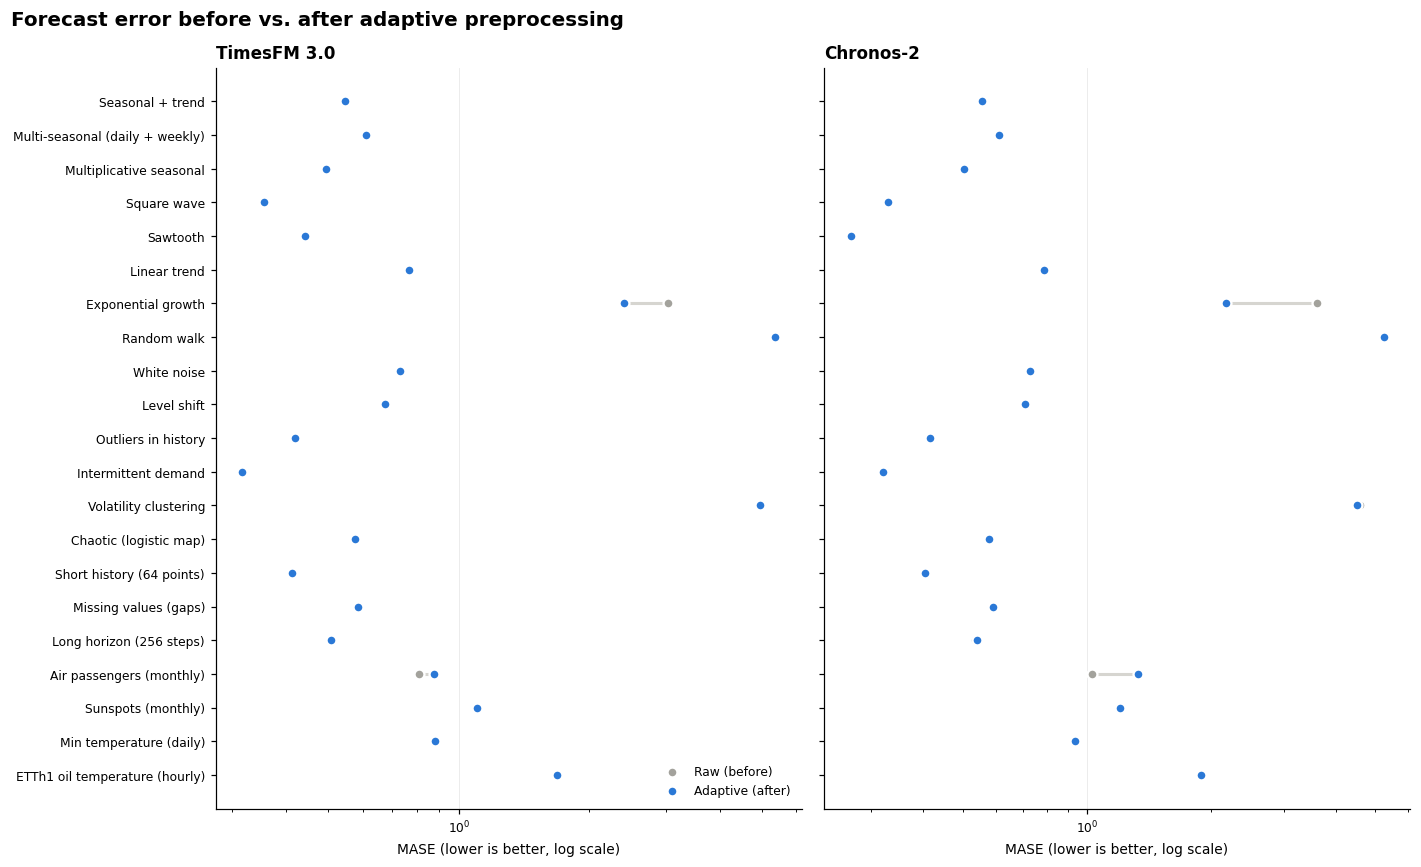

In [ ]:
def dumbbell(ax, before, after, labels, title, xlabel, log=False, target=None):
    y = np.arange(len(labels))[::-1]
    for yi, b, a in zip(y, before, after):
        ax.plot([b, a], [yi, yi], color="#d6d5d0", lw=2, zorder=1, solid_capstyle="round")
    ax.scatter(before, y, s=42, color=C_RAW, zorder=2, label="Raw (before)", edgecolor="white", linewidth=1.5)
    ax.scatter(after, y, s=42, color=C_ADAPT, zorder=3, label="Adaptive (after)", edgecolor="white", linewidth=1.5)
    if target is not None:
        ax.axvline(target, color="#52514e", lw=1, ls=":", zorder=0)
    ax.set_yticks(y, labels)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel(xlabel)
    if log:
        ax.set_xscale("log")
    ax.grid(axis="y", visible=False)


def per_type(model, metric, variant):
    return piv.loc[model, (metric, variant)].reindex(TYPE_ORDER).to_numpy()


fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
for ax, model in zip(axes, MODELS):
    dumbbell(ax, per_type(model, "mase", "Raw"), per_type(model, "mase", "Adaptive"), TYPE_ORDER,
             model, "MASE (lower is better, log scale)", log=True)
axes[0].legend(loc="lower right")
fig.suptitle("Forecast error before vs. after adaptive preprocessing", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/mase_before_after.png", dpi=160, bbox_inches="tight")
plt.show()

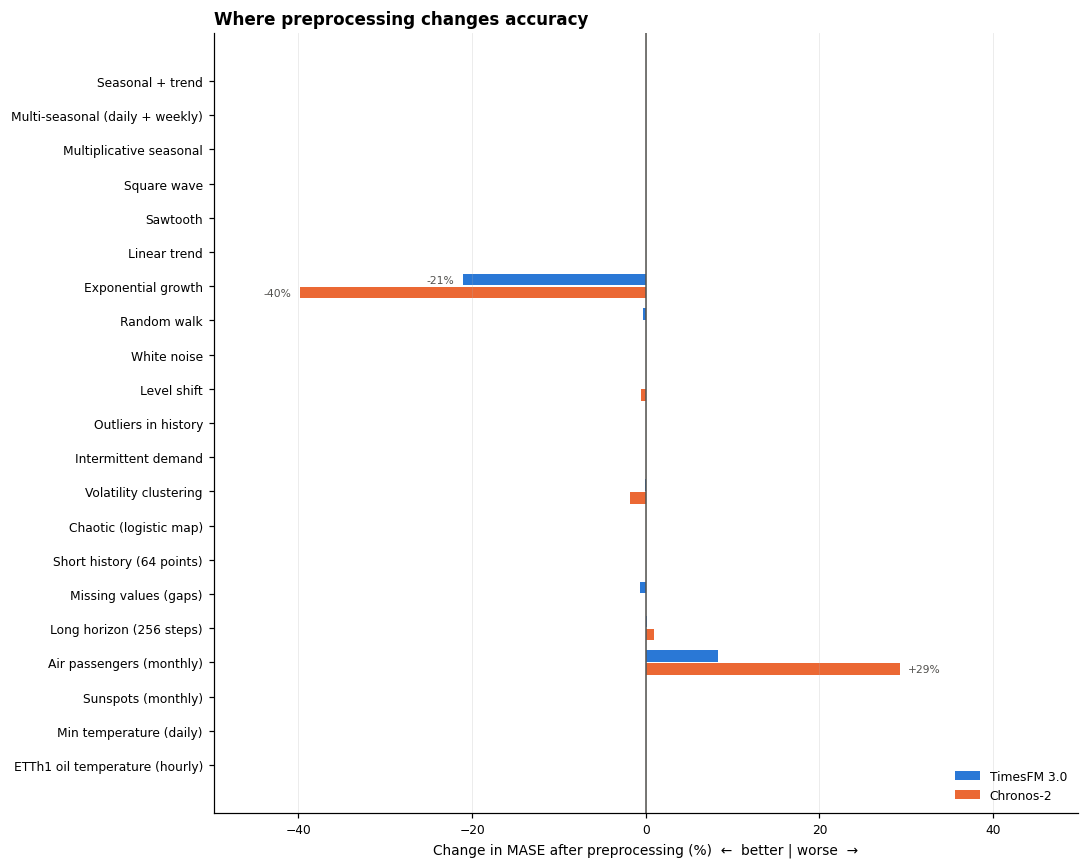

In [ ]:
# Relative change in MASE per data type (negative = preprocessing helped).
change = {m: 100 * (per_type(m, "mase", "Adaptive") / per_type(m, "mase", "Raw") - 1) for m in MODELS}
fig, ax = plt.subplots(figsize=(10, 8))
y = np.arange(len(TYPE_ORDER))[::-1]
bh = 0.38
for i, model in enumerate(MODELS):
    ax.barh(y + (bh / 2 if i == 0 else -bh / 2), change[model], height=bh - 0.04, color=C_MODEL[model], label=model)
for i, model in enumerate(MODELS):
    for yi, v in zip(y, change[model]):
        if abs(v) >= 10:   # label only the meaningful changes
            ax.text(v + (1 if v > 0 else -1), yi + (bh / 2 if i == 0 else -bh / 2), f"{v:+.0f}%",
                    va="center", ha="left" if v > 0 else "right", fontsize=7, color="#52514e")
ax.axvline(0, color="#52514e", lw=1)
lim = np.nanmax(np.abs(np.concatenate(list(change.values()))))
ax.set_xlim(-lim - 10, lim + 10)   # room for the value labels
ax.set_yticks(y, TYPE_ORDER)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Change in MASE after preprocessing (%)  ←  better | worse  →")
ax.set_title("Where preprocessing changes accuracy", loc="left", fontweight="bold")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/mase_change_pct.png", dpi=160, bbox_inches="tight")
plt.show()

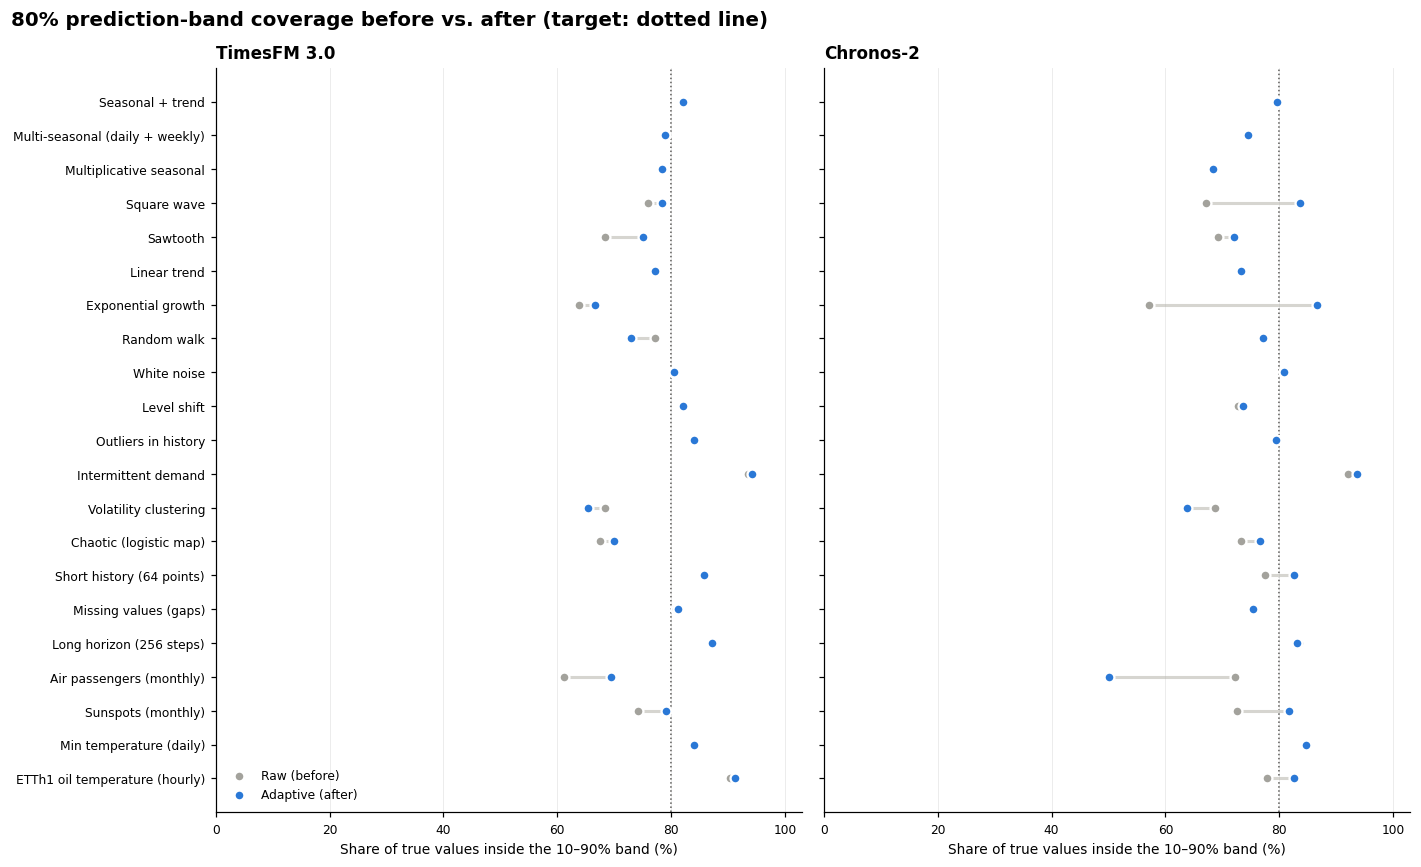

In [ ]:
# Uncertainty: 80% band coverage before vs. after (dotted line = 80% target).
fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
for ax, model in zip(axes, MODELS):
    dumbbell(ax, 100 * per_type(model, "cover", "Raw"), 100 * per_type(model, "cover", "Adaptive"), TYPE_ORDER,
             model, "Share of true values inside the 10–90% band (%)", target=80)
    ax.set_xlim(0, 103)
axes[0].legend(loc="lower left")
fig.suptitle("80% prediction-band coverage before vs. after (target: dotted line)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/coverage_before_after.png", dpi=160, bbox_inches="tight")
plt.show()

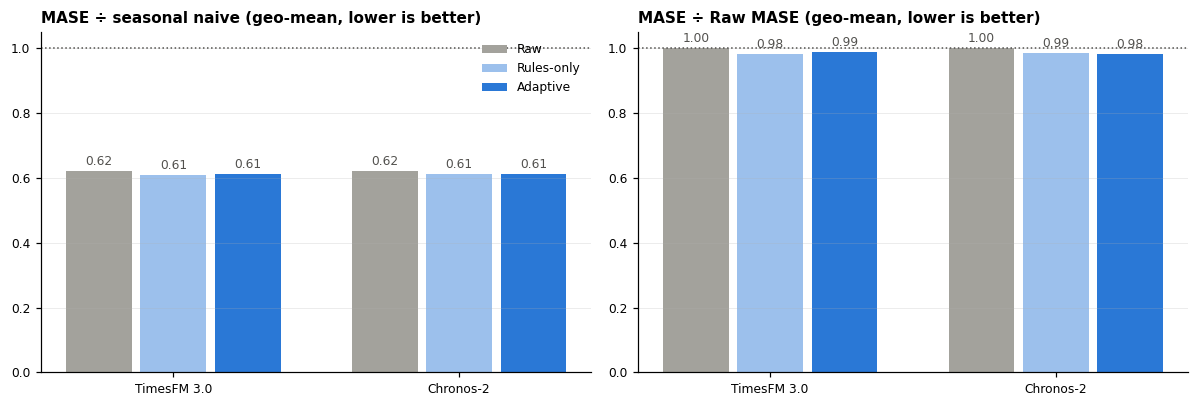

In [ ]:
# Headline: overall error relative to the seasonal-naive baseline, per pipeline variant.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
colors = {"Raw": C_RAW, "Rules-only": C_RULES, "Adaptive": C_ADAPT}
for ax, metric, title in [(axes[0], "MASE / seasonal naive", "MASE ÷ seasonal naive (geo-mean, lower is better)"),
                          (axes[1], "MASE / Raw", "MASE ÷ Raw MASE (geo-mean, lower is better)")]:
    x = np.arange(len(MODELS))
    w = 0.26
    for j, v in enumerate(VARIANTS):
        vals = [overall.loc[f"{metric} ({v})", m] for m in MODELS]
        bars = ax.bar(x + (j - 1) * w, vals, width=w - 0.03, color=colors[v], label=v)
        ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2, color="#52514e")
    ax.set_xticks(x, list(MODELS))
    ax.set_title(title, loc="left", fontsize=10, fontweight="bold")
    ax.grid(axis="x", visible=False)
    ax.axhline(1, color="#52514e", lw=1, ls=":")
axes[0].legend(loc="upper right")
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/overall.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Which preprocessing did the pipeline choose?

Share of series of each type where a step ended up in the **Adaptive** recipe (after the validation gate).

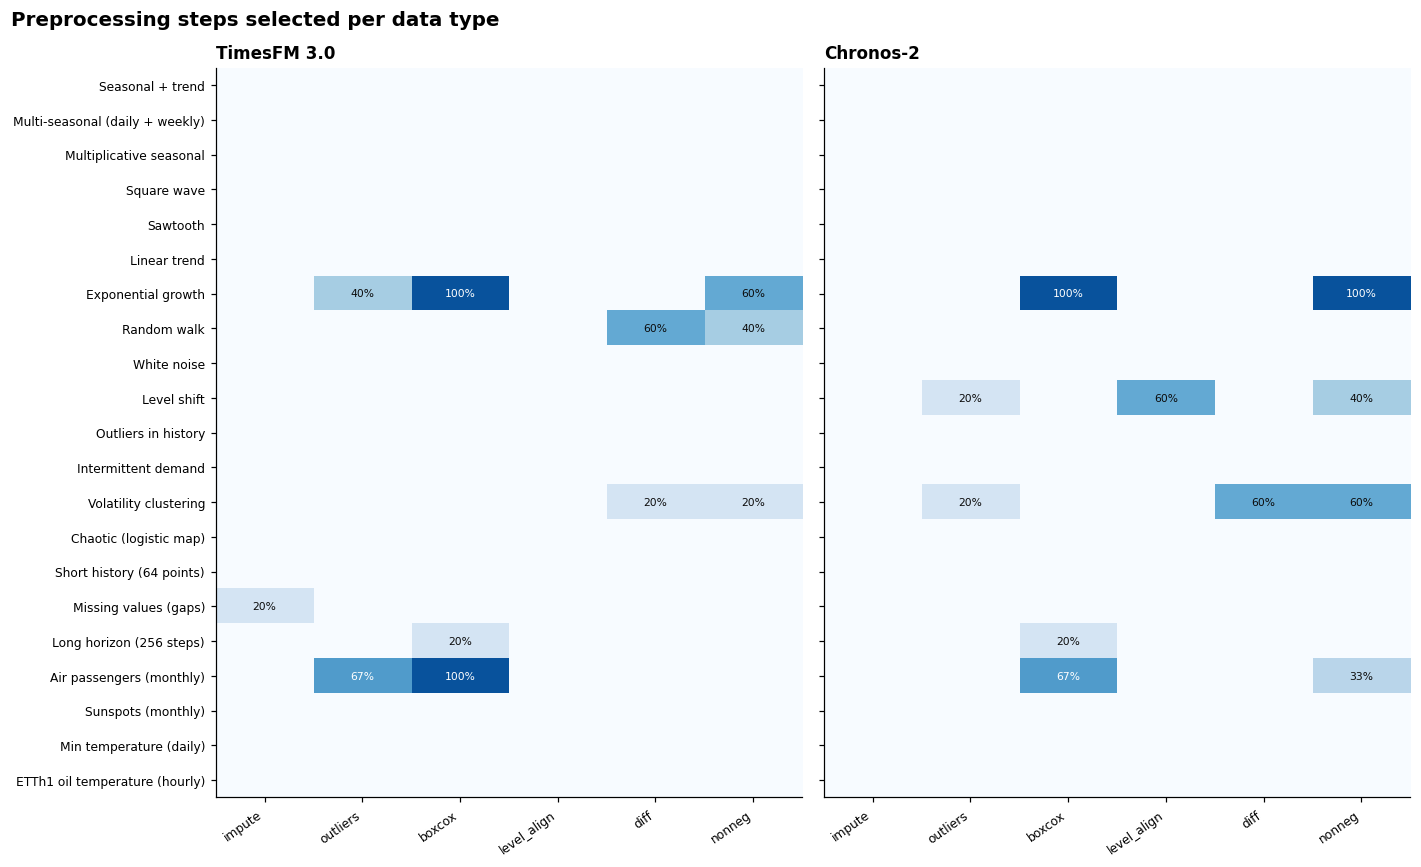

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
for ax, model in zip(axes, MODELS):
    mat = np.array([[np.mean([s in plans[model][t.sid]["chosen"] for t in tasks if t.name == name]) for s in STEP_ORDER]
                    for name in TYPE_ORDER])
    ax.imshow(mat, cmap="Blues", vmin=0, vmax=1.15, aspect="auto")
    for (i, j), v in np.ndenumerate(mat):
        if v > 0:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else "#0b0b0b")
    ax.set_xticks(range(len(STEP_ORDER)), STEP_ORDER, rotation=35, ha="right")
    ax.set_yticks(range(len(TYPE_ORDER)), TYPE_ORDER)
    ax.set_title(model, loc="left", fontweight="bold")
    ax.grid(False)
fig.suptitle("Preprocessing steps selected per data type", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/recipe_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

## 11. Example forecasts: before vs. after

For the data types where preprocessing moved accuracy the most, the series with the largest change is shown for each model.
Black = actual, gray dashed = Raw forecast, blue = Adaptive forecast with its 10–90% band.

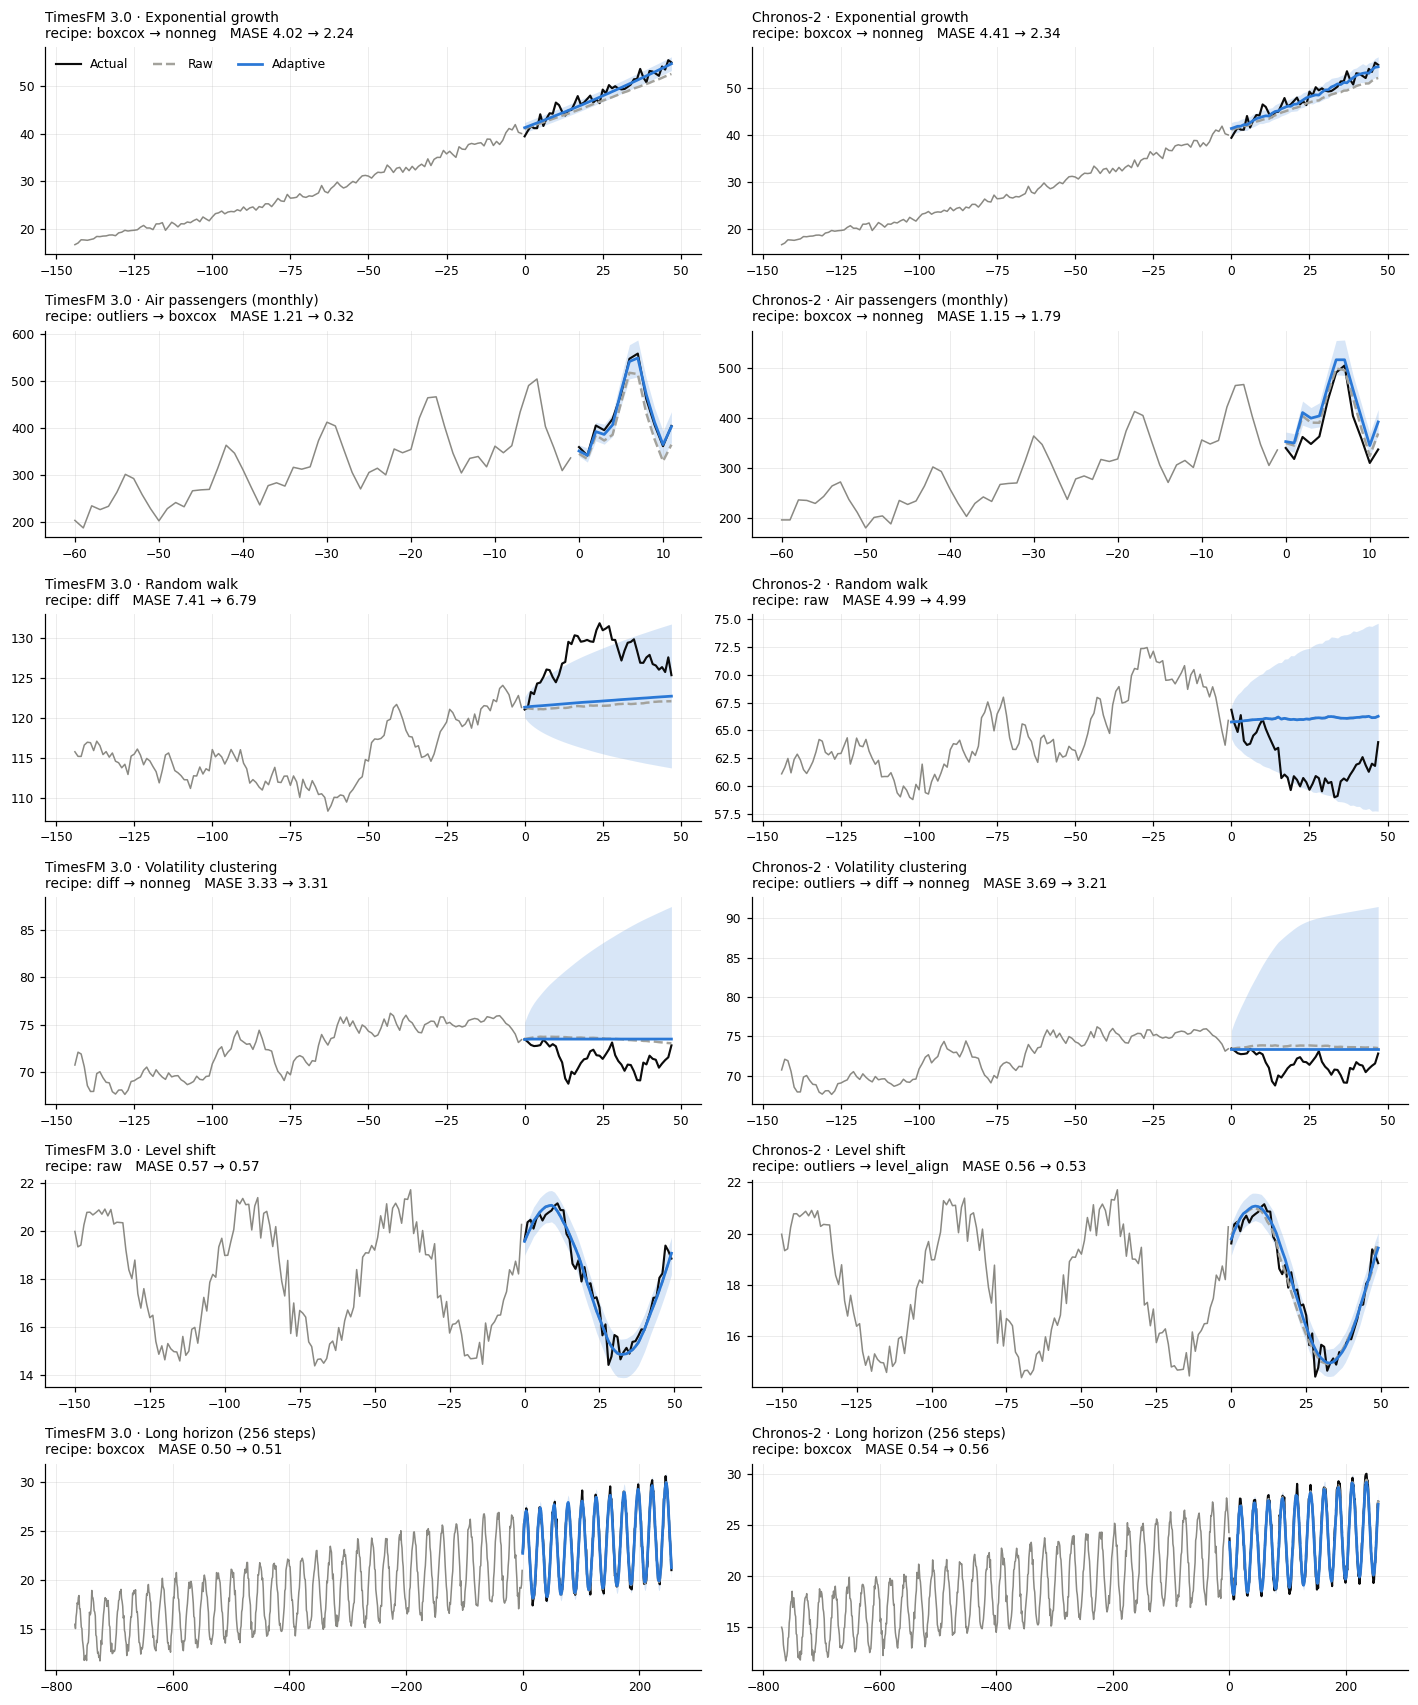

In [ ]:
task_by_id = {t.sid: t for t in tasks}
gain = (wide["Raw"] - wide["Adaptive"]).abs()
type_gain = gain.groupby(gain.index.get_level_values(1).str.split("#").str[0]).mean()
top_types = type_gain.sort_values(ascending=False).index[:6].tolist()

fig, axes = plt.subplots(len(top_types), 2, figsize=(13, 2.6 * len(top_types)))
for r, name in enumerate(top_types):
    for c, model in enumerate(MODELS):
        ax = axes[r, c]
        sids = [t.sid for t in tasks if t.name == name]
        sid = max(sids, key=lambda s: abs(wide.loc[(model, s), "Raw"] - wide.loc[(model, s), "Adaptive"]))
        t = task_by_id[sid]
        h = t.horizon
        k = min(len(t.context), max(3 * h, 2 * t.season, 60))
        xc = np.arange(-k, 0)
        xf = np.arange(h)
        raw, ada = forecasts[(model, sid, "Raw")], forecasts[(model, sid, "Adaptive")]
        ax.plot(xc, t.context[-k:], color="#8a8983", lw=1)
        ax.plot(xf, t.future, color=C_ACTUAL, lw=1.4, label="Actual")
        ax.plot(xf, raw[:, 1], color=C_RAW, lw=1.6, ls="--", label="Raw")
        ax.fill_between(xf, ada[:, 0], ada[:, 2], color=C_ADAPT, alpha=0.18, lw=0)
        ax.plot(xf, ada[:, 1], color=C_ADAPT, lw=1.8, label="Adaptive")
        m_raw, m_ada = wide.loc[(model, sid), "Raw"], wide.loc[(model, sid), "Adaptive"]
        ax.set_title(f"{model} · {name}\nrecipe: {recipe_label(plans[model][sid]['chosen'])}   "
                     f"MASE {m_raw:.2f} → {m_ada:.2f}", loc="left", fontsize=9)
        if r == 0 and c == 0:
            ax.legend(loc="upper left", ncols=3)
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/example_forecasts.png", dpi=160, bbox_inches="tight")
plt.show()

## 12. Findings

Numbers below come from a CPU run of this notebook (GPU kernels can shift them in the last digit).

**Overall.** Adaptive preprocessing lowers the geometric-mean MASE across all 103 forecasts by about **1% for TimesFM 3.0
(×0.989)** and **2% for Chronos-2 (×0.983)**. The validation gate leaves most series untouched; nearly all of the gain
comes from a few data types. Both models already normalize, detrend, interpolate gaps and ignore isolated spikes
internally, so most classical preprocessing is **redundant** for them. That is a useful negative result.

**Where preprocessing helps**
* **Exponential growth → Box-Cox (log):** the largest gain. MASE 3.04 → 2.40 (−21%) for TimesFM and 3.61 → 2.18 (−40%)
  for Chronos-2; Chronos-2's 80% band coverage goes from 57% to 87%. An affine-equivariant model cannot remove
  multiplicative growth by itself.
* **Random walk / volatility clustering → differencing:** small, noisy gains (Rules-only: TimesFM random walk
  5.38 → 5.15, Chronos-2 volatility clustering 4.59 → 4.49). The gate often declines because no method can predict
  these series, which matches the PDF's finding.
* **Level shift → alignment:** Rules-only improves both models slightly (TimesFM 0.68 → 0.66, Chronos-2 0.71 → 0.68).
* **Uncertainty:** widen-only calibration fixes several of the too-narrow bands the PDF flagged (TimesFM sawtooth
  68% → 75%; Chronos-2 square wave 67% → 84%, sunspots 72% → 82%). Mean coverage goes from 78.5% → 79.4% (TimesFM)
  and 75.2% → 77.8% (Chronos-2).

**Where it does not help**
* **Outliers, gaps, short history, seasonal shapes, noise, chaos:** no measurable change. Seasonal imputation for
  TimesFM gains only 0.7% on the gap series, because its built-in interpolation is already good when gaps are short.
* **Air passengers:** Box-Cox passed validation but **hurt** on test (+8% TimesFM, +29% Chronos-2). With 108–132 monthly
  points, three 12-month validation windows are too small to judge a transform reliably.
* **Volatility clustering bands:** the differencing band (√-sum of step widths) assumes independent steps and comes out
  too narrow when volatility clusters (coverage ~65%).

**Recommendation for the team.** For TimesFM 3.0 and Chronos-2, keep preprocessing minimal and targeted:
(1) a variance-stabilizing transform when growth is multiplicative or exponential; (2) differencing only for
unit-root series; (3) widen-only interval calibration; and (4) a validation gate in front of every step, using more
validation windows than three when the series allows. Skip global scaling, detrending, smoothing, context truncation
and outlier repair, because the models already handle those.

**Caveats.** 5 series per synthetic type and 3–5 windows per real dataset, so treat percentages as rough. Defaults
were used for both models, with no covariates.